# Medindo a Eve: BB84 com interceptação e reenvio, QBER em simulação ideal, simulação com ruído e hardware IBM

**Palestra:** *Uma década quântica na nuvem e a contagem regressiva da criptografia* · IBM Qiskit Fall Fest Brasil 2026 (slide 8)
**Autor:** Jullyano Lino · **Versão do Qiskit:** 2.4 (fixada: `qiskit==2.4.2`)

> **Leia antes de rodar (rótulo fixo, igual ao do slide):** este notebook é uma **emulação do protocolo BB84 em circuito**. **Não é QKD fotônico.** Não há fótons, canal óptico, perdas, detectores, fonte real, canal clássico autenticado nem pós-processamento (correção de erros e amplificação de privacidade). O QBER medido aqui mostra duas coisas: (1) a espionagem *intercept-resend* deixa um rastro de erro de ≈ 25% nos bits peneirados; (2) o ruído de portas e de leitura do dispositivo impõe um "chão" de erro mesmo sem espiã.

## O que você vai fazer
1. Construir 24 circuitos que cobrem todas as combinações (bit de Alice, base de Alice, base de Bob, base da Eve ou ausência da Eve).
2. Prever o resultado por contas (≈ 0% sem Eve; ≈ 25% com Eve) e **verificar** em quatro ambientes, do mais limpo ao mais real:

| Modo | O que é | Precisa de conta IBM? |
|---|---|---|
| `ideal` | Simulador sem ruído (Aer) | Não |
| `noisy_custom` | Simulador com ruído parametrizável (você controla `p1`, `p2`, leitura) | Não |
| `noisy_fake` | Simulador com o ruído de um *backend* IBM "congelado" (FakeFez) | Não |
| `hardware` | Computador quântico IBM real, via Qiskit Runtime | **Sim** (API key como *Secret*) |

3. Estimar o QBER com **intervalo de confiança**, comparar os modos e discutir o que o resultado **não** prova.
4. Treinar com exercícios (parâmetros, ruído, métodos novos). Os gabaritos ficam no fim, em células recolhidas.

**Execução padrão segura:** com `RUN_HARDWARE = False` (padrão) nada é enviado a nenhum computador quântico e nenhum segredo é lido. Tempo total dos modos simulados: poucos minutos.

## Sumário
0. Visão geral · 1. Instalação e configuração · 2. Segredos (tokens) · 3. Teoria mínima e previsões · 4. Circuitos · 5. Funções de execução e análise · 6. Simulação ideal · 7. Simulação com ruído · 8. Hardware IBM · 9. Comparação e gráficos · 10. Informação da Eve · 11. Salvar e reproduzir · 12. Exercícios · 13. Gabaritos · 14. Fontes

## 1. Instalação e configuração

As versões abaixo são **fixadas** para reprodutibilidade (testadas em conjunto). Fixar `qiskit==2.4.2` segue o pedido de usar Qiskit 2.4; versões mais novas existem, mas podem mudar APIs.

> No Google Colab, se a instalação pedir, use **Ambiente de execução → Reiniciar sessão** e depois rode a partir daqui.

In [1]:
%pip install -q "qiskit==2.4.2" "qiskit-aer==0.18.2" "qiskit-ibm-runtime==0.52.0" matplotlib scipy pandas pylatexenc

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 3.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 3.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.


In [2]:
import sys, json, math, itertools, platform, datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.stats import binomtest

import qiskit, qiskit_aer, qiskit_ibm_runtime
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit_ibm_runtime import SamplerV2

VERSIONS = {
    "python": platform.python_version(),
    "qiskit": qiskit.__version__,
    "qiskit-aer": qiskit_aer.__version__,
    "qiskit-ibm-runtime": qiskit_ibm_runtime.__version__,
}
print(VERSIONS)
if not qiskit.__version__.startswith("2.4"):
    print("[aviso] Este notebook foi escrito e testado com Qiskit 2.4.x; você está em", qiskit.__version__)

{'python': '3.13.18', 'qiskit': '2.4.2', 'qiskit-aer': '0.18.2', 'qiskit-ibm-runtime': '0.52.0'}


In [29]:
# ---------------- Parâmetros gerais (altere à vontade; veja os exercícios) ----------------
RUN_IDEAL        = True     # simulação ideal (sem ruído)
RUN_NOISY_CUSTOM = True     # simulação com ruído parametrizável
RUN_NOISY_FAKE   = True     # simulação com o ruído de um backend IBM congelado
RUN_HARDWARE     = True    # computador quântico IBM real. Só mude para True depois da seção 2!

SHOTS = 256                # repetições por circuito (24 circuitos => 48.000 shots por modo)
SEED  = 20261110            # semente do transpilador e dos simuladores locais (no hardware real, a amostragem nunca é reprodutível)

# Ruído do modo 'noisy_custom' (ordem de grandeza de dispositivos atuais; ajuste nos exercícios)
P1       = 0.001            # erro depolarizante por porta de 1 qubit (sx, x)
P2       = 0.010            # erro depolarizante por porta de 2 qubits (cx)
READOUT  = 0.020            # probabilidade de leitura errada, simétrica

FAKE_BACKEND_NAME     = "FakeFez"   # backend congelado para 'noisy_fake'
HARDWARE_BACKEND_NAME = None        # ex.: "ibm_fez". None => o menos ocupado entre os que você pode usar

## 2. Segredos (tokens) no Google Colab

Para usar hardware real você precisa de uma **API key** da IBM Quantum Platform e, de preferência, do **CRN da instância** (o plano gratuito *Open* é suficiente). **Nunca cole a chave dentro de uma célula do notebook**: ela iria parar no arquivo `.ipynb` e no histórico de versões.

**Passo a passo (Colab):**
1. Na barra lateral esquerda, clique no ícone de **chave** (*Secrets*/*Segredos*).
2. Clique em **Adicionar novo segredo** e crie:
   - `IBM_CLOUD_TOKEN` → sua API key (criada no painel da IBM Quantum Platform; ela é exibida **uma única vez**).
   - `IBM_CLOUD_INSTANCE` → o CRN (ou o nome) da sua instância, copiado na página *Instances* (opcional, mas evita ambiguidade se você tiver mais de uma).
3. Ative a chave **Acesso ao notebook** de cada segredo. Sem isso o notebook não consegue lê-los.
4. Os segredos **não** são salvos no `.ipynb`; quem copiar o notebook precisa criar os próprios.

**Fora do Colab** (Jupyter local): defina as variáveis de ambiente de mesmo nome ou digite a chave quando o `getpass` pedir (a entrada não aparece na tela).

**Boas práticas:** nunca imprima o token; se ele vazar, revogue-o no painel e crie outro; a conta *Open* tem limite de tempo de QPU (ver seção 8).

*Fontes:* inicialização do serviço com `channel="ibm_quantum_platform"`, `token` e `instance` e onde obter a API key e o CRN: documentação IBM Quantum, *Initialize your account* [F10]. Uso de Secrets do Colab (`google.colab.userdata`) [F11].

In [41]:
import os, getpass

def get_secret(name, prompt=None, required=False):
    """Lê um segredo sem jamais imprimi-lo.
    Ordem: Colab Secrets -> variável de ambiente -> (se required) getpass interativo."""
    value = None
    try:
        from google.colab import userdata            # existe só no Colab
        try:
            value = userdata.get(name)
        except Exception as exc:                       # segredo ausente ou sem 'Acesso ao notebook'
            print(f"[aviso] Segredo '{name}' indisponível no Colab Secrets ({type(exc).__name__}).")
    except ImportError:
        pass
    if not value:
        value = os.environ.get(name)
    if not value and required:
        value = getpass.getpass(prompt or f"{name}: ")
    return value or None

# Teste inofensivo: só informa SE o segredo existe, nunca o valor.
print("IBM_CLOUD_TOKEN presente?", bool(get_secret("IBM_CLOUD_TOKEN")))
print("IBM_CLOUD_INSTANCE presente?", bool(get_secret("IBM_CLOUD_INSTANCE")))

IBM_CLOUD_TOKEN presente? True
IBM_CLOUD_INSTANCE presente? True


## 3. Teoria mínima e previsões numéricas

### 3.1 O protocolo BB84 em uma tela
Alice prepara cada qubit em um de quatro estados, escolhendo **aleatoriamente** o bit $a$ e a base $A$:

| Base | bit 0 | bit 1 |
|---|---|---|
| $Z$ (computacional) | $\lvert 0\rangle$ | $\lvert 1\rangle$ |
| $X$ (Hadamard) | $\lvert +\rangle$ | $\lvert -\rangle$ |

Bob mede cada qubit numa base $B$ também aleatória. Depois, em canal clássico **autenticado**, os dois anunciam as **bases** (nunca os bits) e **peneiram** (*sifting*): ficam só as rodadas com $A=B$ (≈ metade). Sem ruído e sem espiã, os bits peneirados de Alice e Bob coincidem. A fração de discordâncias nos bits peneirados é o **QBER** (*Quantum Bit Error Rate*) [F1].

### 3.2 Por que a Eve deixa rastro
O teorema da não-clonagem diz que não existe operação que copie um estado quântico desconhecido [F2]. Para saber o bit, a Eve tem de **medir**, e medir numa base errada perturba o estado.

**Ataque *intercept-resend*:** a Eve mede cada qubit numa base $E$ (aqui, aleatória) e reenvia a Bob um qubit preparado no resultado que obteve.

- Se $E = A$ (probabilidade ½): ela acerta o bit e reenvia o estado original. Erro de Bob: **0**.
- Se $E \ne A$ (probabilidade ½): o resultado dela é aleatório e o estado reenviado está na base errada. Bob, medindo em $B = A$, erra com probabilidade **½**.

$$\text{QBER}_{\text{Eve}} = \tfrac12\cdot 0 + \tfrac12\cdot\tfrac12 = \tfrac14 = 25\%,\qquad P(\text{Eve acertar o bit}) = \tfrac12\cdot 1 + \tfrac12\cdot\tfrac12 = \tfrac34 .$$

Esse valor (25%) é o resultado clássico do ataque *intercept-resend* no BB84 [F1][F3].

### 3.3 De onde vem o limiar de ≈ 11%
Para o BB84 ideal com erros iguais nas duas bases e pós-processamento unidirecional, a taxa assintótica de chave segura é $r = 1 - 2\,h_2(Q)$, com $h_2$ a entropia binária. Ela é positiva para $Q$ abaixo de ≈ **11%** [F4]. Atenção: é um limiar **idealizado e assintótico** (dispositivos perfeitos, blocos infinitos). Em implementações reais o limite é menor. A célula abaixo calcula o número em vez de apenas citá-lo.

In [31]:
def h2(x):
    return 0.0 if x in (0.0, 1.0) else -x*math.log2(x) - (1-x)*math.log2(1-x)

Q_THRESHOLD = brentq(lambda q: 1 - 2*h2(q), 0.01, 0.2)
print(f"Limiar assintótico (1 - 2*h2(Q) = 0): Q = {Q_THRESHOLD:.4f}  (~{100*Q_THRESHOLD:.1f}%)")
assert abs(Q_THRESHOLD - 0.1100) < 5e-4

Limiar assintótico (1 - 2*h2(Q) = 0): Q = 0.1100  (~11.0%)


### 3.4 Como emular a medição da Eve sem circuitos dinâmicos (medição adiada)
Em vez de medir no meio do circuito, usamos o **princípio da medição adiada**: a medição da Eve na base $E$ equivale a copiar a informação de base $E$ para um **qubit auxiliar** com uma porta CNOT (precedida e seguida de $H$ se $E=X$) e **medir o auxiliar ao final**.

- O estado reduzido do qubit que segue para Bob, depois do CNOT, é o estado **completamente desfasado na base $E$**: $\rho \mapsto \sum_m P_m\rho P_m$. É exatamente a mistura estatística que resultaria de a Eve medir e reenviar o autoestado $\lvert m\rangle_E$ com probabilidade $\langle m\rvert\rho\lvert m\rangle$.
- Logo, as estatísticas de Bob são idênticas às do *intercept-resend*, e o auxiliar, ao ser medido, guarda o palpite da Eve.

**Limites honestos:** é um modelo de **um qubit por rodada**; o canal "reenvia" por construção; não há perda, nem fonte multi-fóton, nem ataque mais esperto que *intercept-resend* (como medição coletiva ou o PNS).

### 3.5 Desenho experimental: 24 circuitos
Variamos todas as combinações: bit $a\in\{0,1\}$, base de Alice $A\in\{Z,X\}$, base de Bob $B\in\{Z,X\}$ e Eve $E\in\{\text{ausente},Z,X\}$:

- sem Eve: $2\times2\times2 = 8$ circuitos; com Eve: $2\times2\times2\times2 = 16$ circuitos; total **24**, cada um com `SHOTS` repetições.
- Escolher bits e bases com probabilidade uniforme equivale a dar **peso igual** a cada combinação. O QBER peneirado é, portanto, a média dos erros nas combinações com $A=B$ (as com $A\ne B$ são descartadas, mas as medimos para mostrar que dão ≈ 50%).
- Incerteza: tratamos erros como binomiais e calculamos o intervalo de **Wilson** a 95% para a taxa agregada. Como as combinações têm taxas diferentes, a variância binomial "agregada" é **conservadora** (superestima um pouco o intervalo). Isso é intencional.

**Previsão por combinação** (com $A=B$): sem Eve → 0; com Eve e $E=A$ → 0; com Eve e $E\ne A$ → ½. Com $A\ne B$ → ½ sempre.

## 4. Os circuitos

Cada circuito tem: o qubit de transmissão `q`, o qubit auxiliar `e` (só é usado quando há Eve) e registradores clássicos `bob` (1 bit) e, quando há Eve, `eve` (1 bit).

1. **Alice:** `X` se $a=1$; `H` se $A=X$.
2. **Eve (opcional):** `H` em `q` se $E=X$; `CX(q→e)`; `H` em `q` se $E=X$; mede `e` em `eve`.
3. **Bob:** `H` em `q` se $B=X$; mede `q` em `bob`.

24 circuitos; 6144 shots por modo


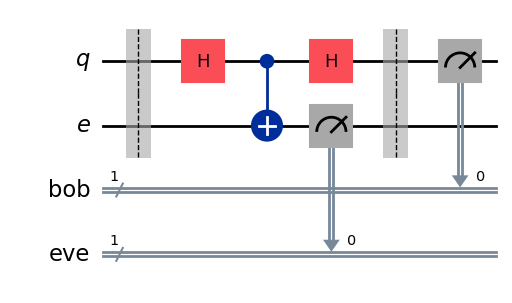

In [32]:
def build_bb84_circuit(a, A, B, E=None):
    """Uma rodada do BB84 com (opcionalmente) a Eve em intercept-resend, por medição adiada.
    a: bit de Alice (0/1). A, B, E: 'Z' ou 'X' (E=None => sem Eve)."""
    q = QuantumRegister(1, "q"); anc = QuantumRegister(1, "e")
    bob = ClassicalRegister(1, "bob")
    regs = [q, anc, bob]
    if E is not None:
        eve = ClassicalRegister(1, "eve"); regs.append(eve)
    qc = QuantumCircuit(*regs, name=f"a{a}_A{A}_B{B}_E{E or 'none'}")
    # Alice
    if a: qc.x(q[0])
    if A == "X": qc.h(q[0])
    qc.barrier()
    # Eve (medição adiada)
    if E is not None:
        if E == "X": qc.h(q[0])
        qc.cx(q[0], anc[0])
        if E == "X": qc.h(q[0])
        qc.measure(anc[0], eve[0])
        qc.barrier()
    # Bob
    if B == "X": qc.h(q[0])
    qc.measure(q[0], bob[0])
    return qc

CELLS = ([(a, A, B, None) for a in (0, 1) for A in "ZX" for B in "ZX"] +
         [(a, A, B, E)    for a in (0, 1) for A in "ZX" for B in "ZX" for E in "ZX"])
CIRCUITS = [build_bb84_circuit(*c) for c in CELLS]
print(len(CIRCUITS), "circuitos;", len(CIRCUITS)*SHOTS, "shots por modo")

# Exemplo: Alice envia |0> (a=0, base Z); Eve mede na base X; Bob mede na base Z.
build_bb84_circuit(0, "Z", "Z", "X").draw("mpl", style="iqp")

## 5. Funções de execução e de análise

- `best_pair(backend)`: escolhe, no *backend*, o par de qubits conectados com menor erro (porta de 2 qubits + leitura do qubit de transmissão). Só usa informação do `target` do próprio *backend*.
- `execute_grid(...)`: transpila os 24 circuitos para o *backend* (opcionalmente com o par escolhido), roda com `SamplerV2` e devolve uma tabela com as contagens.
- **Importante:** `SamplerV2` do Qiskit Runtime roda em **modo de teste local** quando recebe um simulador do Aer ou um *backend* congelado (Fake). Isso permite que **o mesmo código** rode nos quatro modos; só muda o objeto `backend`.

In [33]:
def best_pair(backend, two_q_names=("cz", "ecr", "cx")):
    """Par (tx, anc) conectado com menor [erro 2q + erro de leitura do qubit de transmissão]."""
    t = backend.target
    gate = next(n for n in two_q_names if n in t.operation_names)
    ro = {q: (t["measure"][(q,)].error or 0.0) for q in range(t.num_qubits) if (q,) in t["measure"]}
    best = None
    for (q0, q1), props in t[gate].items():
        if props is None or props.error is None:
            continue
        for tx, anc in ((q0, q1), (q1, q0)):
            score = props.error + ro.get(tx, 1.0)
            if best is None or score < best[0]:
                best = (score, tx, anc, props.error, ro.get(tx, float("nan")))
    _, tx, anc, e2, ero = best
    print(f"[best_pair] porta={gate}  tx={tx}  anc={anc}  erro_2q={e2:.4f}  erro_leitura(tx)={ero:.4f}")
    return [tx, anc]

def transpile_for(backend, circuits, layout=None, opt=1):
    pm = generate_preset_pass_manager(optimization_level=opt, backend=backend,
                                      initial_layout=layout, seed_transpiler=SEED)
    return pm.run(circuits)

def collect(result, cells):
    rows = []
    for (a, A, B, E), pub in zip(cells, result):
        bob = pub.data.bob.get_counts()
        eve = pub.data.eve.get_counts() if E is not None else {}
        rows.append(dict(a=a, A=A, B=B, E=E or "-",
                         bob0=bob.get("0", 0), bob1=bob.get("1", 0),
                         eve0=eve.get("0", 0), eve1=eve.get("1", 0)))
    df = pd.DataFrame(rows)
    df["n"]   = df.bob0 + df.bob1
    df["err"] = np.where(df.a == 0, df.bob1, df.bob0)              # Bob != Alice
    df["eve_ok"] = np.where(df.a == 0, df.eve0, df.eve1)           # palpite da Eve == bit de Alice
    df["p_err"] = df.err / df.n
    return df

def execute_grid(backend, label, shots=SHOTS, layout=None, opt=1, circuits=None, cells=None,
                 sampler_options=None):
    circuits = CIRCUITS if circuits is None else circuits
    cells = CELLS if cells is None else cells
    isa = transpile_for(backend, circuits, layout, opt)
    sampler = SamplerV2(mode=backend)
    if getattr(backend, "service", None) is None:                  # simulador/fake local: fixa a semente (reprodutível)
        sampler.options.simulator.seed_simulator = SEED
    for path, val in (sampler_options or {}).items():             # ex.: {"twirling.enable_measure": True}
        obj = sampler.options; *parents, leaf = path.split(".")
        for p in parents: obj = getattr(obj, p)
        setattr(obj, leaf, val)
    job = sampler.run([(c,) for c in isa], shots=shots)
    try: job_id = job.job_id()
    except Exception: job_id = None
    result = job.result()
    df = collect(result, cells)
    meta = dict(label=label, backend=getattr(backend, "name", str(backend)), job_id=job_id,
                date_utc=dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
                shots=shots, layout=layout, optimization_level=opt, seed=SEED, versions=VERSIONS,
                max_depth=max(c.depth() for c in isa),
                max_2q_gates=max(c.num_nonlocal_gates() for c in isa))
    try: meta["qpu_seconds"] = job.usage()
    except Exception: pass
    return df, meta

def wilson(k, n, conf=0.95):
    ci = binomtest(int(k), int(n)).proportion_ci(confidence_level=conf, method="wilson")
    return ci.low, ci.high

def qber_table(df):
    """QBER peneirado (A=B), com e sem Eve, com IC de Wilson a 95%."""
    s = df[df.A == df.B]
    out = []
    for lab, sub in (("sem Eve", s[s.E == "-"]), ("com Eve", s[s.E != "-"])):
        n, k = int(sub.n.sum()), int(sub.err.sum())
        lo, hi = wilson(k, n)
        out.append({"cenário": lab, "bits_peneirados": n, "erros": k, "QBER": k/n,
                    "IC95_inf": lo, "IC95_sup": hi})
    return pd.DataFrame(out)

def expected_cell(A, B, E):
    """Probabilidade ideal de erro (Bob != Alice) por combinação."""
    if A != B: return 0.5
    if E == "-" or E == A: return 0.0
    return 0.5

RESULTS = {}          # label -> (df, meta)
def register(label, df, meta):
    RESULTS[label] = (df, meta)
    print(f"[{label}] backend={meta['backend']}  job={meta['job_id']}  shots/circ={meta['shots']}")
    display(qber_table(df).round(4))

## 6. Simulação ideal

Aqui o simulador **não tem ruído**. Resultado esperado: **0 erros** nos circuitos sem Eve e ≈ 25% com Eve (flutuação estatística de ≈ 0,3 ponto percentual no QBER agregado com 2000 shots por circuito).

In [34]:
if RUN_IDEAL:
    sim_ideal = AerSimulator(seed_simulator=SEED)
    df_ideal, meta_ideal = execute_grid(sim_ideal, "ideal", layout=None)
    register("ideal", df_ideal, meta_ideal)

    # ---- Verificações automáticas (se algo falhar, há erro de modelagem) ----
    s = df_ideal[df_ideal.A == df_ideal.B]
    assert (s[s.E == "-"].err == 0).all(), "sem Eve e sem ruído não pode haver erro"
    assert (s[(s.E != "-") & (s.E == s.A)].err == 0).all(), "Eve na base certa não gera erro"
    for _, r in df_ideal.iterrows():
        p0 = expected_cell(r.A, r.B, r.E)
        sigma = math.sqrt(max(p0*(1-p0), 1e-12) / r.n)
        assert abs(r.p_err - p0) <= 5*sigma + 1e-9, (r.to_dict(), p0)
    print("Verificações da simulação ideal: OK")

[ideal] backend=aer_simulator  job=e4538af6-41ff-4936-8362-bf566b5776e7  shots/circ=256


,cenário,bits_peneirados,erros,QBER,IC95_inf,IC95_sup
0,sem Eve,1024,0,0.0000,0.0000,0.0037
1,com Eve,2048,505,0.2466,0.2284,0.2657


Verificações da simulação ideal: OK


In [35]:
# Veja a tabela completa das 24 combinações (colunas: bob0/bob1 = contagens da leitura de Bob)
if RUN_IDEAL:
    df_ideal.assign(p_esperada=[expected_cell(r.A, r.B, r.E) for r in df_ideal.itertuples()]).round(4)

## 7. Simulação com ruído

### 7.1 Ruído parametrizável (`noisy_custom`)
Modelo simples e **didático**: erro depolarizante $p_1$ nas portas de 1 qubit (`sx`, `x`), $p_2$ na porta de 2 qubits (`cx`) e erro de leitura simétrico. As portas `rz` são virtuais e sem erro. **Não é** um modelo fiel de nenhum dispositivo: serve para você ver o efeito de cada parâmetro (exercícios 3 e 4).

Regra de bolso (se o ruído for aproximadamente um erro de bit independente com taxa $f$ na leitura): $\text{QBER}_{\text{Eve}}\approx 0{,}25 + 0{,}5\,f$, pois $e' = e + f - 2ef$ com $e=0{,}25$.

In [36]:
def make_noise_model(p1, p2, ro):
    nm = NoiseModel(basis_gates=["rz", "sx", "x", "cx"])
    nm.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ["sx", "x"])
    nm.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cx"])
    nm.add_all_qubit_readout_error(ReadoutError([[1-ro, ro], [ro, 1-ro]]))
    return nm

if RUN_NOISY_CUSTOM:
    sim_noisy = AerSimulator(noise_model=make_noise_model(P1, P2, READOUT), seed_simulator=SEED)
    df_nc, meta_nc = execute_grid(sim_noisy, f"noisy_custom (p1={P1}, p2={P2}, ro={READOUT})")
    register("noisy_custom", df_nc, meta_nc)

[noisy_custom] backend=aer_simulator  job=e7bdd3ff-4d10-4719-b1be-9475280d4bd4  shots/circ=256


,cenário,bits_peneirados,erros,QBER,IC95_inf,IC95_sup
0,sem Eve,1024,14,0.0137,0.0082,0.0228
1,com Eve,2048,536,0.2617,0.2431,0.2812


### 7.2 Ruído de um *backend* IBM congelado (`noisy_fake`)
Os *fake backends* do `qiskit-ibm-runtime` trazem uma **fotografia** da calibração de um dispositivo real. O Aer deriva daí um modelo de ruído (relaxação térmica, erros de porta e de leitura). **Limites:** a fotografia é estática e o modelo não captura tudo (por exemplo, *crosstalk* e deriva temporal), então o resultado é uma **aproximação**, não uma previsão do hardware de hoje.

In [37]:
if RUN_NOISY_FAKE:
    from qiskit_ibm_runtime import fake_provider
    fake = getattr(fake_provider, FAKE_BACKEND_NAME)()
    layout_fake = best_pair(fake)
    df_nf, meta_nf = execute_grid(fake, f"noisy_fake ({fake.name})", layout=layout_fake)
    register("noisy_fake", df_nf, meta_nf)

[best_pair] porta=cz  tx=4  anc=5  erro_2q=0.0028  erro_leitura(tx)=0.0015
[noisy_fake] backend=fake_fez  job=38d1871f-c7a8-47ec-8c02-7b683a300ed0  shots/circ=256


,cenário,bits_peneirados,erros,QBER,IC95_inf,IC95_sup
0,sem Eve,1024,0,0.0000,0.0000,0.0037
1,com Eve,2048,518,0.2529,0.2346,0.2722


## 8. Hardware real da IBM

### Antes de rodar
- **Custo/limite:** o plano gratuito *Open* dá o equivalente a **até 10 minutos de tempo de QPU por janela móvel de 28 dias** [F12]. Este experimento envia **48.000 shots** em **um único *job*** (24 circuitos × 2000). O tempo de QPU consumido depende do *backend*; o notebook imprime `job.usage()` ao final para você conferir. Em vez de supor, **confira em *Usage*** no painel da IBM.
- **Modo de execução:** usamos *job mode* (sem *session*), compatível com o plano gratuito.
- **Segredos:** a célula lê `IBM_QUANTUM_API_KEY` (e `IBM_QUANTUM_INSTANCE`, se existir) **sem imprimir**.
- **Sem *circuitos dinâmicos*:** a Eve usa medição adiada, então não há medição no meio do circuito.
- **Ordem recomendada:** rode os modos simulados primeiro; só depois mude `RUN_HARDWARE = True` na seção 1 e rode **apenas** esta célula.

### Escolha do par de qubits
Só importa o erro do qubit de transmissão (lido por Bob) e da porta CNOT da Eve. Por isso `best_pair` busca o par conectado com menor erro somado; com isso o "chão" medido nos circuitos sem Eve é o melhor que o dispositivo oferece naquele dia.

In [42]:
if RUN_HARDWARE:
    from qiskit_ibm_runtime import QiskitRuntimeService
    _token = get_secret("IBM_CLOUD_TOKEN", prompt="IBM_CLOUD_TOKEN: ", required=True)
    _instance = get_secret("IBM_CLOUD_INSTANCE")
    _kw = dict(channel="ibm_quantum_platform", token=_token)
    if _instance: _kw["instance"] = _instance
    service = QiskitRuntimeService(**_kw)
    del _token, _kw                                      # não deixe o token à mão
    avail = service.backends(simulator=False, operational=True, min_num_qubits=2)
    print("Backends disponíveis para você:", [b.name for b in avail])
    hw = (service.backend(HARDWARE_BACKEND_NAME) if HARDWARE_BACKEND_NAME
          else service.least_busy(simulator=False, operational=True, min_num_qubits=2))
    print("Backend escolhido:", hw.name)
    layout_hw = best_pair(hw)
    df_hw, meta_hw = execute_grid(hw, f"hardware ({hw.name})", layout=layout_hw)
    register("hardware", df_hw, meta_hw)
else:
    print("RUN_HARDWARE = False: nenhuma conexão com a IBM foi feita.")

qiskit_runtime_service._discover_account:WARNING:2026-11-10 02:17:08,700: Loading account with the given token. A saved account will not be used.


Backends disponíveis para você: ['ibm_fez', 'ibm_kingston', 'ibm_marrakesh']
Backend escolhido: ibm_fez
[best_pair] porta=cz  tx=114  anc=115  erro_2q=0.0021  erro_leitura(tx)=0.0010
[hardware] backend=ibm_fez  job=dbp7tbk4148s739u3ao0  shots/circ=256


,cenário,bits_peneirados,erros,QBER,IC95_inf,IC95_sup
0,sem Eve,1024,7,0.0068,0.0033,0.0140
1,com Eve,2048,541,0.2642,0.2455,0.2837


> **Rodar em duas etapas (opcional):** se a fila estiver longa, você pode enviar o *job*, anotar o `job_id` e recuperar o resultado depois com `service.job(job_id).result()`. O `job_id` fica salvo nos metadados do experimento (seção 11) e é o "recibo" que torna o dado verificável.

## 9. Comparação e gráficos
Os gráficos incluem sempre o rótulo "emulação do protocolo em circuito, não QKD fotônico". O nome do *backend*, o `job_id` e a data só aparecem para o modo hardware (que é onde eles existem).

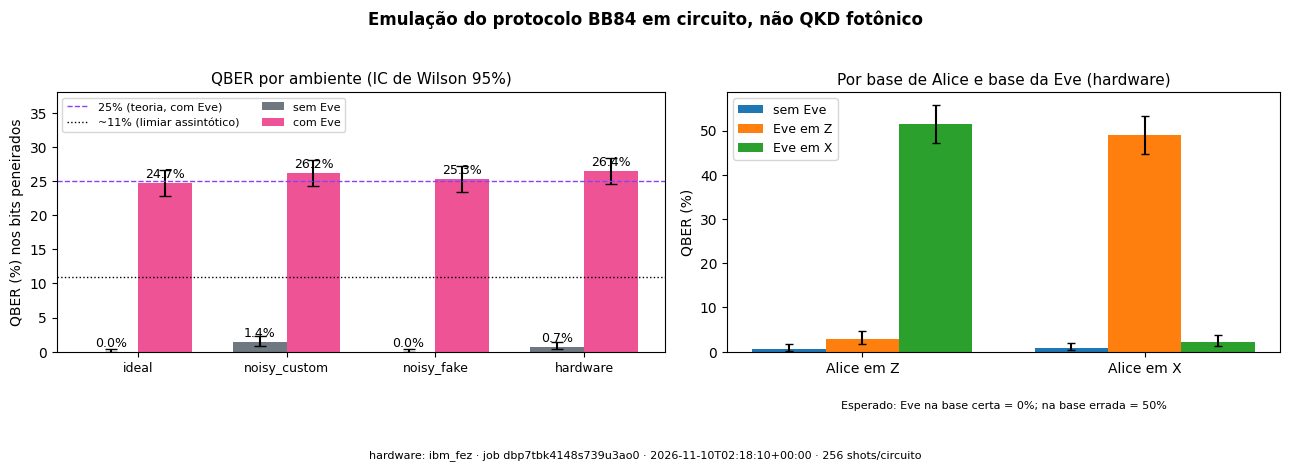

In [43]:
def plot_comparison(results, savepath=None):
    labels = list(results.keys())
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
    # (a) QBER agregado, sem e com Eve
    ax = axes[0]; w = 0.36; x = np.arange(len(labels))
    for i, (scen, color) in enumerate((("sem Eve", "#6f7780"), ("com Eve", "#ee5396"))):
        vals, lo, hi = [], [], []
        for lab in labels:
            t = qber_table(results[lab][0]).set_index("cenário").loc[scen]
            vals.append(100*t.QBER); lo.append(100*(t.QBER-t.IC95_inf)); hi.append(100*(t.IC95_sup-t.QBER))
        ax.bar(x + (i-0.5)*w, vals, w, yerr=[lo, hi], capsize=4, color=color, label=scen)
        for xi, v in zip(x + (i-0.5)*w, vals): ax.text(xi, v+0.8, f"{v:.1f}%", ha="center", fontsize=9)
    ax.axhline(25, ls="--", color="#8a3ffc", lw=1, label="25% (teoria, com Eve)")
    ax.axhline(100*Q_THRESHOLD, ls=":", color="k", lw=1, label=f"~{100*Q_THRESHOLD:.0f}% (limiar assintótico)")
    ax.set_xticks(x); ax.set_xticklabels([l.split(" (")[0] for l in labels], rotation=0, fontsize=9)
    ax.set_ylabel("QBER (%) nos bits peneirados"); ax.set_ylim(0, 38); ax.legend(loc="upper left", fontsize=8, ncol=2)
    ax.set_title("QBER por ambiente (IC de Wilson 95%)", fontsize=11)
    # (b) por base de Alice e base da Eve, no último ambiente listado
    ax = axes[1]; lab = labels[-1]; df = results[lab][0]; s = df[(df.A == df.B)]
    groups = [("sem Eve", s[s.E == "-"].groupby("A")), ("Eve em Z", s[s.E == "Z"].groupby("A")), ("Eve em X", s[s.E == "X"].groupby("A"))]
    xx = np.arange(2); ww = 0.26
    for i, (name, g) in enumerate(groups):
        k = g.err.sum(); n = g.n.sum()
        p = (k/n).reindex(["Z", "X"]) * 100
        ci = [wilson(k[b], n[b]) for b in ("Z", "X")]
        ax.bar(xx + (i-1)*ww, p.values, ww, yerr=[[p.values[j]-100*ci[j][0] for j in range(2)], [100*ci[j][1]-p.values[j] for j in range(2)]], capsize=3, label=name)
    ax.set_xticks(xx); ax.set_xticklabels(["Alice em Z", "Alice em X"]); ax.set_ylabel("QBER (%)")
    ax.set_title(f"Por base de Alice e base da Eve ({lab.split(' (')[0]})", fontsize=11); ax.legend(fontsize=9)
    ax.text(0.5, -0.22, "Esperado: Eve na base certa = 0%; na base errada = 50%", transform=ax.transAxes, ha="center", fontsize=8)
    fig.suptitle("Emulação do protocolo BB84 em circuito, não QKD fotônico", fontsize=12, fontweight="bold")
    hw = [r for r in results if r.startswith("hardware")]
    if hw:
        m = results[hw[0]][1]
        fig.text(0.5, 0.005, f"hardware: {m['backend']} · job {m['job_id']} · {m['date_utc']} · {m['shots']} shots/circuito", ha="center", fontsize=8)
    fig.tight_layout(rect=[0, 0.03, 1, 0.95])
    if savepath: fig.savefig(savepath, dpi=200)
    plt.show()

if RESULTS:
    plot_comparison(RESULTS, savepath="qber_comparacao.png")

In [44]:
if RESULTS:
    summary = pd.concat({lab: qber_table(df).set_index("cenário") for lab, (df, _) in RESULTS.items()}).round(4)
    display(summary)
    # Chão do dispositivo (sem Eve) e quanto a Eve soma por cima
    for lab, (df, _) in RESULTS.items():
        t = qber_table(df).set_index("cenário")
        print(f"{lab:>14}: chão = {100*t.loc['sem Eve','QBER']:.2f}%   com Eve = {100*t.loc['com Eve','QBER']:.2f}%   "
              f"regra de bolso 25% + 0,5*chão = {100*(0.25 + 0.5*t.loc['sem Eve','QBER']):.2f}%")

bits_peneirados  erros    QBER  IC95_inf  IC95_sup
             cenário                                                    
ideal        sem Eve             1024      0  0.0000    0.0000    0.0037
             com Eve             2048    505  0.2466    0.2284    0.2657
noisy_custom sem Eve             1024     14  0.0137    0.0082    0.0228
             com Eve             2048    536  0.2617    0.2431    0.2812
noisy_fake   sem Eve             1024      0  0.0000    0.0000    0.0037
             com Eve             2048    518  0.2529    0.2346    0.2722
hardware     sem Eve             1024      7  0.0068    0.0033    0.0140
             com Eve             2048    541  0.2642    0.2455    0.2837

         ideal: chão = 0.00%   com Eve = 24.66%   regra de bolso 25% + 0,5*chão = 25.00%
  noisy_custom: chão = 1.37%   com Eve = 26.17%   regra de bolso 25% + 0,5*chão = 25.68%
    noisy_fake: chão = 0.00%   com Eve = 25.29%   regra de bolso 25% + 0,5*chão = 25.00%
      hardware: chão = 0.68%   com Eve = 26.42%   regra de bolso 25% + 0,5*chão = 25.34%


### Como ler o resultado (e o que ele **não** prova)
- **Ideal:** sem Eve, erro exatamente 0; com Eve, ≈ 25%. É a confirmação numérica da conta da seção 3.
- **Com ruído:** aparece um **chão** nos circuitos sem Eve; o QBER com Eve sobe um pouco acima de 25% (regra de bolso: +0,5 × chão). A Eve continua **claramente separada** do chão, desde que o chão seja pequeno.
- **Detectabilidade ≠ segurança.** Este experimento mostra que a espionagem *intercept-resend* é **detectável** neste modelo. Não prova que o QKD seja seguro na prática: faltam fonte real, canal clássico autenticado, estimativa com blocos finitos, correção de erros, amplificação de privacidade e proteção contra ataques de canal lateral [F3].
- **Se o chão chegar perto do limiar (≈ 11%)**, o protocolo deixa de produzir chave mesmo sem Eve; a Eve e o ruído se confundem. Esse é o ponto do exercício 3.

## 10. O que a Eve aprendeu?
O qubit auxiliar guarda o palpite da Eve. Nas rodadas peneiradas ($A=B$): acerta 100% quando $E=A$ e 50% quando $E\ne A$, em média **75%**. A Eve não sabe quais rodadas serão peneiradas até as bases serem anunciadas, mas, como $E$ é independente de $A$, a estatística é essa. Em contrapartida, ela paga com QBER de 25%: **informação e perturbação andam juntas.**

In [45]:
def eve_accuracy(df):
    s = df[(df.A == df.B) & (df.E != "-")]
    k, n = int(s.eve_ok.sum()), int((s.eve0 + s.eve1).sum())
    lo, hi = wilson(k, n)
    return k/n, lo, hi

for lab, (df, _) in RESULTS.items():
    p, lo, hi = eve_accuracy(df)
    print(f"{lab:>14}: Eve acerta {100*p:.1f}%  [IC95 {100*lo:.1f}%, {100*hi:.1f}%]   (teoria: 75%)")

         ideal: Eve acerta 75.2%  [IC95 73.3%, 77.1%]   (teoria: 75%)
  noisy_custom: Eve acerta 74.2%  [IC95 72.3%, 76.1%]   (teoria: 75%)
    noisy_fake: Eve acerta 74.9%  [IC95 73.0%, 76.7%]   (teoria: 75%)
      hardware: Eve acerta 73.2%  [IC95 71.2%, 75.1%]   (teoria: 75%)


## 11. Salvar e reproduzir (o "pacote reproduzível")
Guardamos **contagens brutas + metadados** (versões, semente, par de qubits, `job_id`, data). Com o arquivo você refaz a análise **sem reexecutar nada** (inclusive o do hardware). Se um dia você publicar um repositório, leve junto este arquivo `.json` e a figura.

In [46]:
def export_results(path="bb84_qber_resultados.json"):
    payload = {lab: {"meta": meta, "data": df.to_dict("records")} for lab, (df, meta) in RESULTS.items()}
    with open(path, "w", encoding="utf-8") as f:
        json.dump(payload, f, ensure_ascii=False, indent=2, default=str)
    print("salvo em", path)
    return path

def load_results(path):
    with open(path, encoding="utf-8") as f:
        payload = json.load(f)
    return {lab: (pd.DataFrame(v["data"]), v["meta"]) for lab, v in payload.items()}

if RESULTS:
    saved = export_results()
    reloaded = load_results(saved)
    for lab in RESULTS:                                    # a análise a partir do arquivo tem de ser idêntica
        assert qber_table(RESULTS[lab][0]).equals(qber_table(reloaded[lab][0]))
    print("Reanálise a partir do JSON: idêntica.")
    try:                                                   # no Colab, baixa o arquivo e a figura
        from google.colab import files
        files.download(saved); files.download("qber_comparacao.png")
    except Exception:
        pass

salvo em bb84_qber_resultados.json
Reanálise a partir do JSON: idêntica.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Exercícios

Cada exercício tem um *esqueleto* e uma verificação automática (que imprime "pendente" enquanto você não implementar). Resolva primeiro, depois compare com a seção 13. Use sempre o simulador ideal ou o ruidoso; **não gaste cota de hardware** com exercícios, exceto o 6.

### Exercício 1 · Parâmetros: quantos shots são necessários?
A largura do intervalo de confiança cai como $1/\sqrt{n}$. **(a)** Varie `SHOTS` em {100, 500, 2000, 10000} no simulador ideal e plote a largura do IC (de Wilson) do QBER com Eve em escala log-log; **(b)** estime a inclinação (esperada ≈ −0,5); **(c)** supondo que o QBER observado com Eve seja exatamente 25% e que o limiar seja um número **fixo** (sem incerteza), qual o menor número de bits peneirados para que o IC95 de Wilson fique **inteiramente acima** de 11%? E acima de um chão fixo de 5%? (Atenção: o chão real também tem incerteza; este é um mínimo otimista.)

In [ ]:
# --- Exercício 1: esqueleto ---
def ci_width_vs_shots(shots_list):
    """Devolva uma lista com a largura (IC95_sup - IC95_inf) do QBER 'com Eve' para cada valor de shots."""
    widths = []
    # TODO: para cada s em shots_list: execute_grid(AerSimulator(seed_simulator=SEED), "ex1", shots=s) e use qber_table(...)
    return widths

w = ci_width_vs_shots([100, 500, 2000, 10000])
print("Exercício 1:", "pendente" if not w else [round(x, 4) for x in w])

### Exercício 2 · Método novo: Monte Carlo do protocolo (sem Qiskit) e ataque parcial
Implemente `simulate_bb84(n, f, rng)`: sorteia bits e bases de Alice, bases de Bob; com probabilidade `f` a Eve intercepta (base aleatória, mede e reenvia); peneira $A=B$ e devolve o QBER. **Verifique:** `f=1` → 0,25; `f=0,4` → 0,10 (ataque parcial: QBER $=0{,}25 f$). Compare com a saída dos circuitos. **Pergunta:** que fração `f` a Eve pode interceptar sem ser detectada, se o chão do dispositivo for 2% e você aceitar até 5% de QBER total?

In [ ]:
# --- Exercício 2: esqueleto ---
def simulate_bb84(n, f, rng):
    """Retorne o QBER peneirado de n rodadas, com a Eve interceptando cada rodada com probabilidade f."""
    # TODO
    return None

rng = np.random.default_rng(SEED)
r1 = simulate_bb84(200_000, 1.0, rng); r2 = simulate_bb84(200_000, 0.4, rng)
if r1 is None: print("Exercício 2: pendente")
else: print("Exercício 2:", "OK" if abs(r1-0.25) < 0.005 and abs(r2-0.10) < 0.005 else f"revise (obtido {r1:.3f} e {r2:.3f})")

### Exercício 3 · Ruído: até onde a Eve é distinguível?
No modo `noisy_custom`, varie `READOUT` e `P2` (ex.: `READOUT` de 0 a 0,15) e plote o QBER **sem Eve** e **com Eve**. **(a)** A partir de que `READOUT` o chão passa do limiar de ≈ 11%? **(b)** Compare o QBER com Eve medido com a regra de bolso $0{,}25 + 0{,}5 f$. **(c)** Ele continua distinguível do chão a 5σ quando o chão está em 8%? Discuta em duas frases por que "a Eve se esconde no ruído" só se o ruído for suficiente *e* ela interceptar uma fração pequena.

In [ ]:
# --- Exercício 3: esqueleto ---
def sweep_readout(values):
    """Devolva lista de tuplas (readout, QBER_sem_Eve, QBER_com_Eve) usando make_noise_model e execute_grid."""
    out = []
    # TODO
    return out

res3 = sweep_readout([0.0, 0.02, 0.05, 0.10])
print("Exercício 3:", "pendente" if not res3 else [(r, round(a, 3), round(b, 3)) for r, a, b in res3])

### Exercício 4 · Generalizar a Eve: eixo de medição qualquer
Até aqui a Eve mede em $Z$ ou $X$. Generalize: ela mede ao longo do eixo $\hat n(\theta)=(\sin\theta,0,\cos\theta)$ (plano $xz$ da esfera de Bloch). Use `ry(-theta)` no qubit, `cx` para o auxiliar e `ry(theta)`. **Preveja** (derive!) o erro de Bob e a taxa de acerto da Eve em função de $\theta$ para $A=Z$ e para $A=X$, e confirme numericamente. *Dica:* para estado de Alice com eixo $\hat a$, o erro de Bob é $(1-(\hat a\cdot\hat n)^2)/2$. **Pergunta:** qual $\theta$ maximiza a informação da Eve? O QBER depende de $\theta$?

In [ ]:
# --- Exercício 4: esqueleto ---
def build_bb84_circuit_theta(a, A, B, theta):
    """Como build_bb84_circuit, mas a Eve mede ao longo de n(theta) = (sin θ, 0, cos θ)."""
    # TODO: copie build_bb84_circuit e troque o bloco da Eve
    return None

c = build_bb84_circuit_theta(0, "Z", "Z", 0.3)
print("Exercício 4:", "pendente" if c is None else "circuito criado: agora varie theta e compare com a previsão")

### Exercício 5 · Método novo: decisão com margem estatística
Implemente `eve_detectada(df, k_sigma=5)` que devolve `True` se o limite **inferior** do IC (a $k_\sigma$ desvios) do QBER medido **com** Eve estiver acima do limite **superior** do QBER medido **sem** Eve por pelo menos 5 pontos percentuais, e `False` caso contrário. Teste em `ideal`, `noisy_custom` e `noisy_fake`. Em que regime de ruído ela falha?

In [ ]:
# --- Exercício 5: esqueleto ---
def eve_detectada(df, k_sigma=5, margem=0.05):
    # TODO: use qber_table(df); para k_sigma desvios use z = k_sigma e aproximação normal sobre o QBER agregado
    return None

if RESULTS:
    out = {lab: eve_detectada(df) for lab, (df, _) in RESULTS.items()}
    print("Exercício 5:", "pendente" if all(v is None for v in out.values()) else out)

### Exercício 6 · Hardware (só se tiver cota): o par de qubits importa?
Rode `execute_grid` no mesmo *backend* com **(i)** o par de `best_pair` e **(ii)** um par conectado qualquer com erro de leitura alto (escolha olhando `backend.target`). Compare o chão (QBER sem Eve). Repita com `sampler_options={"twirling.enable_measure": True}` e discuta se a mitigação de leitura reduziu o chão. Reporte `job_id`, data e `backend` de cada execução. **Cuide da cota:** cada execução usa 48.000 shots.

### Exercício 7 · Conceitual (responda em texto)
1. Por que medir os circuitos com $A\ne B$ **não** entra no QBER?
2. Cite três ingredientes de um sistema QKD real que este notebook **não** modela.
3. O que mudaria se a Eve interceptasse com **uma base fixa** em vez de aleatória? (Dica: faça a conta para $E=Z$ sempre.)
4. Por que 11% é limiar **assintótico** e idealizado, e o que tende a acontecer com ele em blocos finitos?

## 13. Gabaritos
As células abaixo estão **recolhidas** (formulário do Colab). Tente primeiro. Elas rodam no simulador, portanto não gastam cota.

In [ ]:
#@title Gabarito do exercício 1 (clique para expandir)
def ci_width_vs_shots_sol(shots_list):
    widths = []
    for s in shots_list:
        df, _ = execute_grid(AerSimulator(seed_simulator=SEED), "ex1", shots=s)
        t = qber_table(df).set_index("cenário").loc["com Eve"]
        widths.append(t.IC95_sup - t.IC95_inf)
    return widths

sl = [100, 500, 2000, 10000]
w = ci_width_vs_shots_sol(sl)
slope = np.polyfit(np.log(sl), np.log(w), 1)[0]
print("larguras:", [round(x, 4) for x in w], " inclinação log-log:", round(slope, 3), "(esperado ~ -0,5)")
assert -0.6 < slope < -0.4
# (c) separar 25% de 11% a 95%: IC de Wilson inferior > 0.11
def min_bits(p, thr, conf=0.95):
    n = 10
    while wilson(round(p*n), n, conf)[0] <= thr: n += 10
    return n
print("bits peneirados mínimos (otimista, limiar fixo) p/ IC95 de 25% ficar acima de 11%:", min_bits(0.25, 0.11))
print("bits peneirados mínimos (otimista, limiar fixo) p/ IC95 de 25% ficar acima de 5%:", min_bits(0.25, 0.05))

In [ ]:
#@title Gabarito do exercício 2
def simulate_bb84_sol(n, f, rng):
    a = rng.integers(0, 2, n); A = rng.integers(0, 2, n); B = rng.integers(0, 2, n)
    intercept = rng.random(n) < f
    E = rng.integers(0, 2, n)
    bit_in_transit = a.copy()
    basis_in_transit = A.copy()
    # Eve mede: base certa -> bit certo; base errada -> bit aleatório; reenvia na base E
    eve_bit = np.where(E == A, a, rng.integers(0, 2, n))
    bit_in_transit = np.where(intercept, eve_bit, bit_in_transit)
    basis_in_transit = np.where(intercept, E, basis_in_transit)
    # Bob mede: base de transmissão igual à dele -> bit; senão aleatório
    bob_bit = np.where(basis_in_transit == B, bit_in_transit, rng.integers(0, 2, n))
    sift = A == B
    return float(np.mean(bob_bit[sift] != a[sift]))

rng = np.random.default_rng(SEED)
print("f=1.0:", simulate_bb84_sol(200_000, 1.0, rng), " f=0.4:", simulate_bb84_sol(200_000, 0.4, rng))
assert abs(simulate_bb84_sol(200_000, 1.0, rng) - 0.25) < 0.005 and abs(simulate_bb84_sol(200_000, 0.4, rng) - 0.10) < 0.005
# Pergunta: QBER_total = chão + 0.25 f (aprox.) <= 5%  =>  f <= (0.05 - 0.02)/0.25 = 0.12 (a Eve intercepta até ~12% sem exceder o orçamento de 5%)
print("f máxima sob orçamento de 5% com chão de 2%:", (0.05 - 0.02) / 0.25)

In [ ]:
#@title Gabarito do exercício 3
def sweep_readout_sol(values):
    out = []
    for r in values:
        sim = AerSimulator(noise_model=make_noise_model(P1, P2, r), seed_simulator=SEED)
        df, _ = execute_grid(sim, f"ex3 ro={r}")
        t = qber_table(df).set_index("cenário")
        out.append((r, t.loc["sem Eve", "QBER"], t.loc["com Eve", "QBER"]))
    return out

vals = [0.0, 0.02, 0.05, 0.10, 0.12, 0.15]
res = sweep_readout_sol(vals)
for r, a, b in res:
    print(f"readout={r:.2f}  sem Eve={100*a:5.2f}%  com Eve={100*b:5.2f}%  regra de bolso={100*(0.25+0.5*a):5.2f}%")
# (a) o chão (sem Eve) passa de 11% quando o erro de leitura + erro de portas passa de ~11%.
# (c) com chão 8%: com Eve ~ 29%: separados por ~21 pontos, muitíssimos sigmas com n ~ 8000.

In [ ]:
#@title Gabarito do exercício 4
def build_bb84_circuit_theta_sol(a, A, B, theta):
    q = QuantumRegister(1, "q"); anc = QuantumRegister(1, "e")
    bob = ClassicalRegister(1, "bob"); eve = ClassicalRegister(1, "eve")
    qc = QuantumCircuit(q, anc, bob, eve)
    if a: qc.x(q[0])
    if A == "X": qc.h(q[0])
    qc.ry(-theta, q[0]); qc.cx(q[0], anc[0]); qc.ry(theta, q[0])      # Eve mede ao longo de n(theta)
    qc.measure(anc[0], eve[0])
    if B == "X": qc.h(q[0])
    qc.measure(q[0], bob[0])
    return qc

sim = AerSimulator(seed_simulator=SEED)
rows = []
for th in np.linspace(0, np.pi/2, 7):
    cells = [(a, A, A, "theta") for a in (0, 1) for A in "ZX"]
    circs = [build_bb84_circuit_theta_sol(a, A, A, th) for (a, A, _, _) in cells]
    isa = transpile_for(sim, circs)
    smp = SamplerV2(mode=sim); smp.options.simulator.seed_simulator = SEED
    res = smp.run([(c,) for c in isa], shots=20000).result()
    err_, ok_, n_ = 0, 0, 0
    for (a, A, _, _), pub in zip(cells, res):
        b = pub.data.bob.get_counts(); e = pub.data.eve.get_counts()
        err_ += b.get(str(1-a), 0); ok_ += e.get(str(a), 0); n_ += sum(b.values())
    pred_err = 0.25                                      # (sin^2θ/2 + cos^2θ/2)/2 = 1/4 para qualquer θ
    pred_acc = (2 + np.cos(th) + np.sin(th)) / 4          # média de (1+cosθ)/2 [A=Z] e (1+sinθ)/2 [A=X]
    rows.append((th, err_/n_, pred_err, ok_/n_, pred_acc))
    assert abs(err_/n_ - pred_err) < 0.01 and abs(ok_/n_ - pred_acc) < 0.01
print(pd.DataFrame(rows, columns=["theta", "QBER", "QBER_prev", "acerto_Eve", "acerto_prev"]).round(4))
print("max da informação da Eve em theta = pi/4:", (2 + np.sqrt(2)) / 4, " (base de Breidbart); QBER = 25% para todo theta")

In [ ]:
#@title Gabarito do exercício 5
def eve_detectada_sol(df, k_sigma=5, margem=0.05):
    t = qber_table(df).set_index("cenário")
    def inf_sup(row):
        p, n = row.QBER, row.bits_peneirados
        sd = math.sqrt(p*(1-p)/n)
        return p - k_sigma*sd, p + k_sigma*sd
    lo_eve, _ = inf_sup(t.loc["com Eve"]); _, hi_floor = inf_sup(t.loc["sem Eve"])
    return bool(lo_eve > hi_floor + margem)

print({lab: eve_detectada_sol(df) for lab, (df, _) in RESULTS.items()})
# Falha quando o chão é tão alto que (QBER_eve - chão) < margem + incertezas: o que só ocorre com chão ~ >40%
# ou quando a Eve intercepta fração pequena (f << 1): ver o exercício 2 (QBER ~ chão + 0,25 f).

**Respostas curtas do exercício 7:** (1) Quando $A\ne B$ o resultado de Bob é aleatório por construção; incluí-lo mediria só o desacordo de bases, não a espionagem. (2) Fonte de fótons únicos (e ataque PNS), canal óptico com perdas e detectores, canal clássico autenticado, correção de erros, amplificação de privacidade, estimativa com blocos finitos, defesa contra canais laterais (qualquer três). (3) Com $E=Z$ fixo, o erro é ½ só quando $A=X$, logo $\tfrac12\cdot\tfrac12=25\%$ de novo: o QBER médio é o mesmo, mas Alice e Bob podem detectar a assimetria **por base** (0% em Z, 50% em X), por isso conferir o QBER **separado por base** é uma boa prática. (4) É o limite quando o número de rodadas vai a infinito e o dispositivo é ideal; com blocos finitos, é preciso margem estatística e o limiar efetivo cai.

## 14. Fontes
Entradas marcadas ✔ foram **abertas e conferidas nesta sessão de produção** (página original ou do registro oficial). As demais são referências clássicas citadas pelos dados bibliográficos usuais; confira antes de citar em publicação.

| Ref. | Fonte | Verificada |
|---|---|---|
| [F1] | C. H. Bennett, G. Brassard, *Quantum cryptography: Public key distribution and coin tossing* (BB84, 1984); reedição: Theor. Comput. Sci. 560, 7–11 (2014), DOI 10.1016/j.tcs.2014.05.025; arXiv:2003.06557 | ✔ arXiv e DOI |
| [F2] | W. K. Wootters, W. H. Zurek, *A single quantum cannot be cloned*, Nature 299, 802–803 (1982), DOI 10.1038/299802a0; D. Dieks, Phys. Lett. A 92, 271 (1982) | não reaberta |
| [F3] | V. Scarani et al., *The security of practical quantum key distribution*, Rev. Mod. Phys. 81, 1301 (2009), DOI 10.1103/RevModPhys.81.1301; arXiv:0802.4155. Ver também C. H. Bennett et al., *Experimental quantum cryptography*, J. Cryptology 5, 3–28 (1992) | ✔ (RMP); Bennett et al. não reaberta |
| [F4] | P. W. Shor, J. Preskill, *Simple proof of security of the BB84 quantum key distribution protocol*, Phys. Rev. Lett. 85, 441 (2000), DOI 10.1103/PhysRevLett.85.441; arXiv:quant-ph/0003004 (o valor ≈ 11% é recalculado na seção 3.3) | ✔ registro; limiar recalculado |
| [F10] | IBM Quantum Documentation, *Initialize your account*: https://quantum.cloud.ibm.com/docs/en/guides/initialize-account | ✔ |
| [F11] | Colab Secrets: ícone de chave → *Add new secret* → ativar *Notebook access*; leitura com `google.colab.userdata.get`. Guia: https://www.alura.com.br/artigos/google-colab-gerenciamento-informacoes-sensiveis | ✔ (passos); exceções específicas: ver documentação oficial do Colab |
| [F12] | IBM Quantum Platform, *Plans overview* (Open Plan: até 10 min de QPU por janela de 28 dias): https://quantum.cloud.ibm.com/docs/guides/plans-overview | ✔ |
| [F13] | IBM Quantum Platform, *Manage instances* (seleção por CRN/nome; requer qiskit-ibm-runtime ≥ 0.40.1): https://quantum.cloud.ibm.com/docs/guides/instances | ✔ |
| [F14] | Pacotes: `qiskit==2.4.2`, `qiskit-aer==0.18.2`, `qiskit-ibm-runtime==0.52.0` (PyPI) | ✔ (instalados e executados) |

**Reprodutibilidade:** este notebook foi **executado de ponta a ponta** (modos ideal, ruído parametrizável e ruído de *backend* congelado) com as versões acima antes de ser entregue. O modo `hardware` usa o mesmo código (`execute_grid`), mas não pôde ser executado nessa verificação por exigir credenciais; por isso o `job_id` e os números do hardware só passam a existir quando **você** rodar.